# Кластеризация статей по эмбеддингам

Запустите все ячейки из корня репозитория после `pip install -r requirements.txt`.
OpenAI API и повторное вычисление эмбеддингов не нужны.

Сравниваем **DBSCAN** и **HDBSCAN** (иерархическое развитие DBSCAN для разной плотности).
По умолчанию экспортируем HDBSCAN: он не требует единого радиуса `eps`, но параметры
`min_cluster_size` и `min_samples` всё равно нужно подбирать по смыслу статей.
Метка `-1` означает шум, а не отдельный тематический кластер.

Кластеризация выполняется в исходном пространстве L2-нормализованных эмбеддингов.
Евклидово расстояние здесь связано с cosine distance: `d_euclidean² = 2 * d_cosine`.
PCA и t-SNE используются только для отображения: расстояния между группами на t-SNE
не являются мерой семантической близости. У плотностных алгоритмов в высокой
размерности результат может быть чувствителен к параметрам и содержать много шума.


In [5]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

# Сначала абсолютный путь пользователя, затем стандартный путь репозитория.
INDEX_PATH = Path('/data/train/train_index_summarized.csv')
if not INDEX_PATH.is_file():
    INDEX_PATH = Path('data/train/train_index_summarized.csv')
ARTICLES_DIR = INDEX_PATH.parent / 'files'
OUTPUT_DIR = Path('data/clustering')
RANDOM_STATE = 42
DBSCAN_EPS = 0.9  # cosine distance = 0.405 для нормализованных векторов
MIN_SAMPLES = 5  # включает саму точку в обеих реализациях sklearn
MIN_CLUSTER_SIZE = 10
EXPORT_ALGORITHM = 'hdbscan'  # либо 'dbscan'
TSNE_MAX_POINTS = 5000  # только визуализация; экспорт и кластеризация используют все строки
TSNE_PERPLEXITY = 30.0


## Загрузка и проверка

CSV содержит `id`, `summary`, `embedding`; эмбеддинг — JSON-массив.
Ошибочные строки не удаляются молча: выполнение останавливается с идентификатором.
Названия берутся из первого Markdown-заголовка статьи; при отсутствии файла — из `id`.
Порядок строк CSV сохраняется во всех экспортируемых файлах.


In [6]:
def load_index(path):
    if not path.is_file():
        raise FileNotFoundError(f'{path}: сначала запустите prepare-train-data.ipynb')
    frame = pd.read_csv(path, dtype={'id': str})
    missing = {'id', 'summary', 'embedding'} - set(frame.columns)
    if missing:
        raise ValueError(f'Отсутствуют колонки: {sorted(missing)}')
    if len(frame) < 3:
        raise ValueError('Нужны минимум 3 статьи для PCA и t-SNE')
    if frame['id'].isna().any() or frame['id'].duplicated().any():
        raise ValueError('id должны быть заполнены и уникальны')
    vectors = []
    dimension = None
    for article_id, value in zip(frame['id'], frame['embedding']):
        try:
            vector = np.asarray(json.loads(value), dtype=np.float32)
            if vector.ndim != 1 or vector.size < 2 or not np.isfinite(vector).all():
                raise ValueError('нужен конечный одномерный вектор размерности >= 2')
            if np.linalg.norm(vector) == 0:
                raise ValueError('нулевой вектор')
            if dimension is not None and vector.size != dimension:
                raise ValueError('размерности эмбеддингов не совпадают')
            dimension = vector.size
        except (TypeError, ValueError) as exc:
            raise ValueError(f'Некорректный embedding для {article_id}: {exc}') from exc
        vectors.append(vector)
    return frame, np.stack(vectors)


def article_title(article_id):
    # Не позволяем id из CSV читать файлы вне каталога статей.
    path = ARTICLES_DIR / (Path(article_id).name + '.md')
    if path.is_file():
        for line in path.read_text(encoding='utf-8').splitlines():
            if re.match(r'^#{1,6}\s+', line):
                return re.sub(r'^#{1,6}\s+', '', line).strip()
    return re.sub(r'^\d+_', '', article_id).replace('_', ' ')


index_df, embeddings = load_index(INDEX_PATH)
X = normalize(embeddings, norm='l2')
index_df['title'] = index_df['id'].map(article_title)
print(f'{len(index_df)} статей, {X.shape[1]} измерений; индекс: {INDEX_PATH}')
display(index_df[['id', 'title']].head())


657 статей, 1536 измерений; индекс: data/train/train_index_summarized.csv


,id,title
0,0002_Scaling_Catalog_Attribute_Extraction_with...,Scaling Catalog Attribute Extraction with Mult...
1,0003_Introducing_PIXEL_Instacart’s_Unified_Ima...,Introducing PIXEL: Instacart’s Unified Image G...
2,0004_From_failure_to_success_The_birth_of_Grab...,"From failure to success: The birth of GrabGPT,..."
3,0007_Turbocharging_Customer_Support_Chatbot_De...,Turbocharging Customer Support Chatbot Develop...
4,0008_How_Delivery_Hero_Uses_Agentic_AI_for_Bui...,How Delivery Hero Uses Agentic AI for Building...


## Подбор параметров и кластеризация

На графике расстояний до k-го соседа ищите перегиб для стартового `DBSCAN_EPS`,
затем проверяйте состав кластеров. Автоматического универсального порога нет.
Для большого индекса DBSCAN может потребовать квадратичную память; HDBSCAN также
может быть дорогим в высокой размерности. Ограничение t-SNE не ограничивает эти затраты.


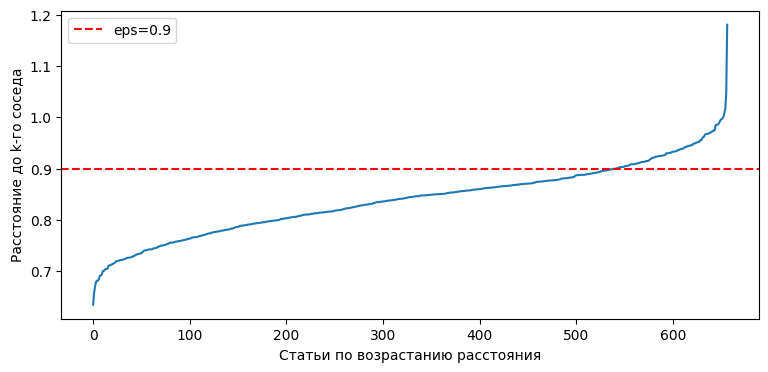

,algorithm,clusters,noise_count,noise_fraction
0,dbscan,1,36,0.054795
1,hdbscan,2,508,0.773212


,size,examples
cluster,,
-1,508,[Scaling Catalog Attribute Extraction with Mul...
0,133,[Turbocharging Customer Support Chatbot Develo...
1,16,"[The AI behind Uplift, Leverage graph technolo..."


In [7]:
if not 2 <= MIN_SAMPLES <= len(X):
    raise ValueError('MIN_SAMPLES должен быть от 2 до числа статей')
if not 2 <= MIN_CLUSTER_SIZE <= len(X):
    raise ValueError('MIN_CLUSTER_SIZE должен быть от 2 до числа статей')
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='euclidean').fit(X)
distances, _ = neighbors.kneighbors(X)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.sort(distances[:, -1]))
ax.axhline(DBSCAN_EPS, color='red', linestyle='--', label=f'eps={DBSCAN_EPS}')
ax.set(xlabel='Статьи по возрастанию расстояния', ylabel='Расстояние до k-го соседа')
ax.legend()
plt.show()

labels_by_algorithm = {
    'dbscan': DBSCAN(eps=DBSCAN_EPS, min_samples=MIN_SAMPLES,
                     metric='euclidean', n_jobs=-1).fit_predict(X),
    'hdbscan': HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES,
                       metric='euclidean', n_jobs=-1).fit_predict(X),
}
summary = pd.DataFrame([
    {'algorithm': name, 'clusters': len(set(labels) - {-1}),
     'noise_count': int((labels == -1).sum()), 'noise_fraction': float((labels == -1).mean())}
    for name, labels in labels_by_algorithm.items()
])
display(summary)
if EXPORT_ALGORITHM not in labels_by_algorithm:
    raise ValueError('EXPORT_ALGORITHM: выберите dbscan или hdbscan')
labels = labels_by_algorithm[EXPORT_ALGORITHM]
if len(set(labels) - {-1}) < 2:
    print('Найдено меньше двух кластеров: измените параметры и проверьте статьи.')
clustered = index_df[['id', 'title', 'summary']].copy()
for name, values in labels_by_algorithm.items():
    clustered[f'cluster_{name}'] = values
clustered['cluster'] = labels
clustered['is_noise'] = labels == -1
display(clustered.groupby('cluster', sort=True).agg(
    size=('id', 'size'), examples=('title', lambda s: list(s.head(5)))))


## PCA и t-SNE

Одинаковая воспроизводимая выборка для обоих графиков и алгоритмов.
PCA обучается на всех статьях. Для ускорения t-SNE сначала снижаем размерность до 50
компонент PCA. Шум показан серым; номера кластеров произвольны и не сопоставимы
между алгоритмами. Для полного просмотра названий используйте Projector.


t-SNE: 657 статей, perplexity=30.0
PCA: объяснённая дисперсия двух компонент = 10.5%


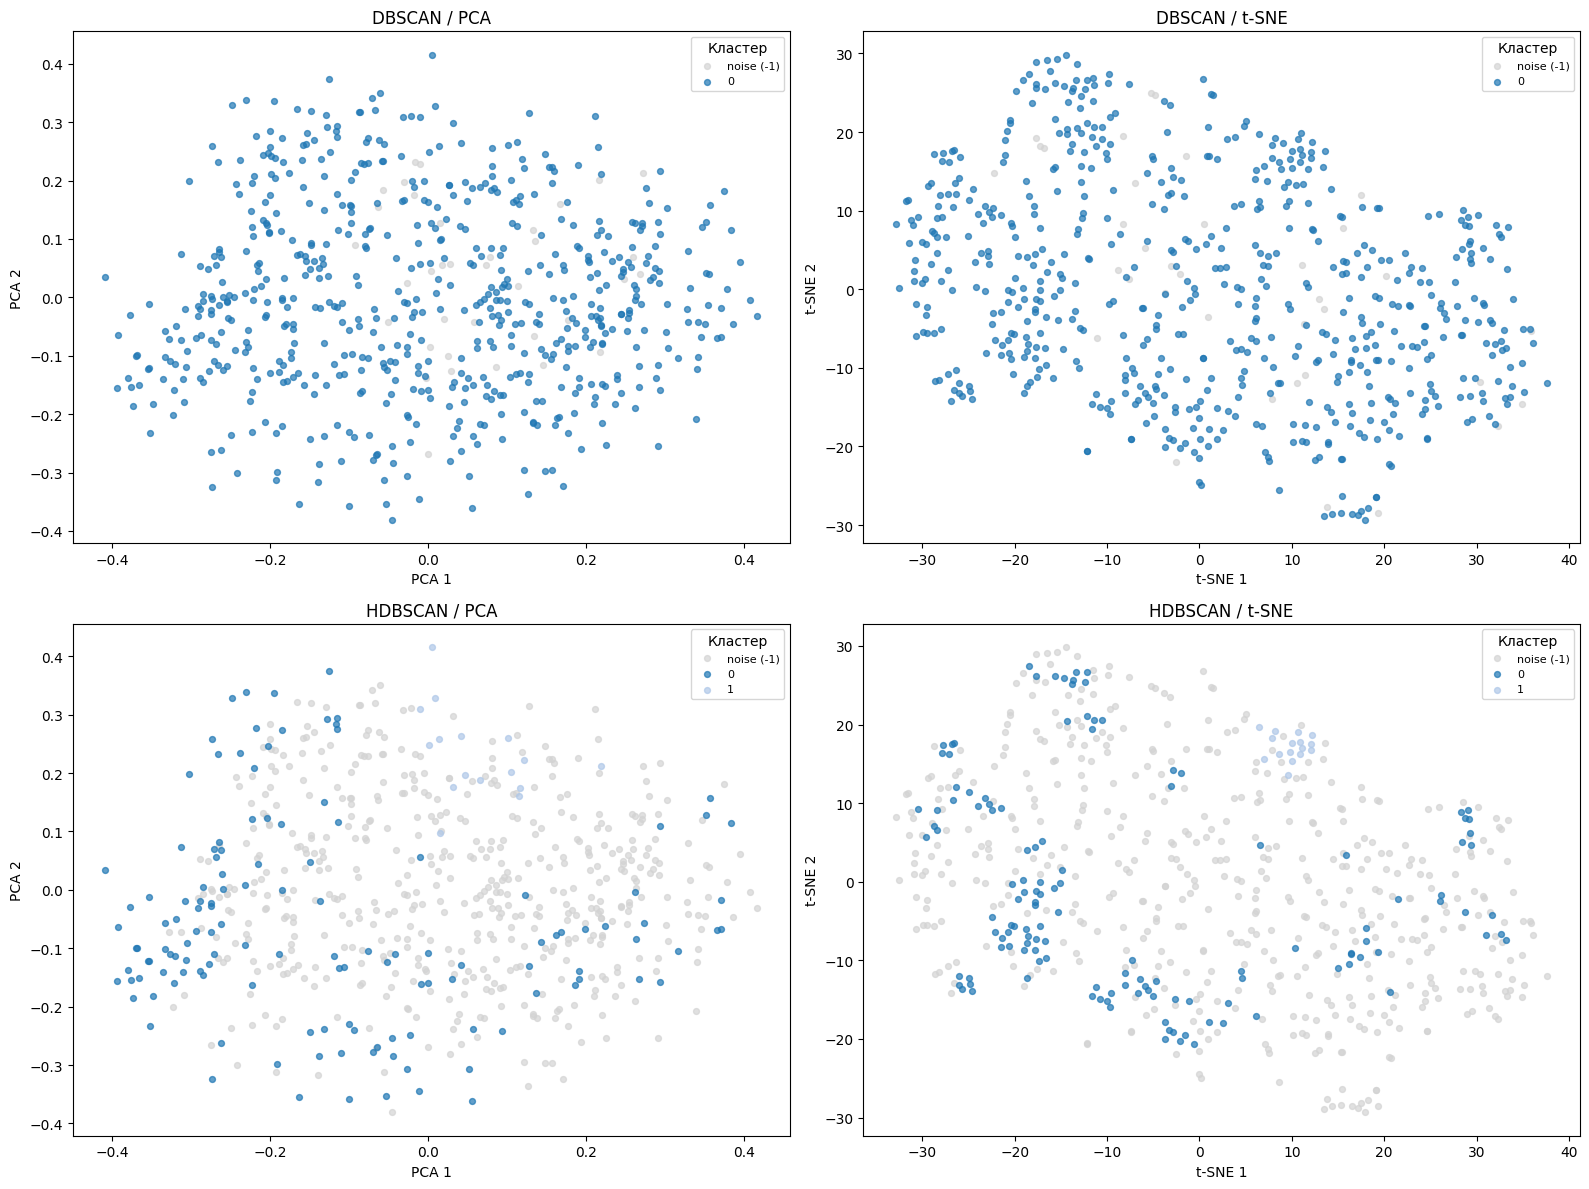

In [8]:
if TSNE_MAX_POINTS < 3 or TSNE_PERPLEXITY <= 0:
    raise ValueError('TSNE_MAX_POINTS >= 3 и TSNE_PERPLEXITY > 0 обязательны')
rng = np.random.default_rng(RANDOM_STATE)
plot_rows = np.sort(rng.choice(len(X), size=min(len(X), TSNE_MAX_POINTS), replace=False))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_xy = pca.fit_transform(X)
tsne_input = PCA(n_components=min(50, len(plot_rows), X.shape[1]),
                 random_state=RANDOM_STATE).fit_transform(X[plot_rows])
perplexity = min(TSNE_PERPLEXITY, float(len(plot_rows) - 1))
tsne_xy = TSNE(n_components=2, perplexity=perplexity, init='pca',
               learning_rate='auto', random_state=RANDOM_STATE).fit_transform(tsne_input)
print(f't-SNE: {len(plot_rows)} статей, perplexity={perplexity}')
print(f'PCA: объяснённая дисперсия двух компонент = {pca.explained_variance_ratio_.sum():.1%}')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for row, (name, all_labels) in enumerate(labels_by_algorithm.items()):
    sampled_labels = all_labels[plot_rows]
    unique_clusters = sorted(set(all_labels) - {-1})
    colors = {c: plt.get_cmap('tab20')(i % 20) for i, c in enumerate(unique_clusters)}
    for col, (projection, coords) in enumerate([('PCA', pca_xy[plot_rows]), ('t-SNE', tsne_xy)]):
        ax = axes[row, col]
        for c in sorted(set(sampled_labels)):
            mask = sampled_labels == c
            ax.scatter(coords[mask, 0], coords[mask, 1], s=18, alpha=0.7,
                       color='lightgray' if c == -1 else colors[c],
                       label='noise (-1)' if c == -1 else str(c))
        ax.set(title=f'{name.upper()} / {projection}', xlabel=f'{projection} 1', ylabel=f'{projection} 2')
        if len(set(sampled_labels)) <= 20:
            ax.legend(title='Кластер', fontsize=8)
fig.tight_layout()
plt.show()


## Экспорт в TensorFlow Embedding Projector

Экспортируются **все статьи**, включая шум, в исходном порядке:

- `vectors.tsv`: исходные эмбеддинги, без заголовка и индекса;
- `metadata.tsv`: заголовок и поля `id`, `title`, `cluster`, `is_noise`, метки обоих алгоритмов;
- `clusters.csv`: названия, summaries и результаты для локального анализа;
- `run_config.json`: параметры для воспроизводимости.

Откройте https://projector.tensorflow.org/ → **Load** → выберите `vectors.tsv`
как tensor, а `metadata.tsv` как metadata. Для окраски выберите `cluster`, для подписи
`title`. Загрузка на сайт выполняется пользователем вручную.


In [11]:
clustered_original = clustered.copy()

In [12]:
clustered['id'] = clustered['summary']
clustered.head()

,id,title,summary,cluster_dbscan,cluster_hdbscan,cluster,is_noise
0,Платформа на основе мультимодальной LLM для се...,Scaling Catalog Attribute Extraction with Mult...,Платформа на основе мультимодальной LLM для се...,0,-1,-1,True
1,Платформа для масштабного создания и автоматич...,Introducing PIXEL: Instacart’s Unified Image G...,Платформа для масштабного создания и автоматич...,0,-1,-1,True
2,Внутренний сервис с поддержкой нескольких LLM ...,"From failure to success: The birth of GrabGPT,...",Внутренний сервис с поддержкой нескольких LLM ...,0,-1,-1,True
3,Система на базе больших языковых моделей автом...,Turbocharging Customer Support Chatbot Develop...,Система на базе больших языковых моделей автом...,0,0,0,False
4,Сервис на базе агентного ИИ для автоматическог...,How Delivery Hero Uses Agentic AI for Building...,Сервис на базе агентного ИИ для автоматическог...,0,-1,-1,True


In [13]:
def clean_tsv_text(value):
    return re.sub(r'[\t\r\n]+', ' ', str(value))


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metadata = clustered[['id', 'title', 'cluster', 'is_noise', 'cluster_dbscan', 'cluster_hdbscan']].copy()
for column in ['id', 'title']:
    metadata[column] = metadata[column].map(clean_tsv_text)
assert len(metadata) == len(embeddings)
np.savetxt(OUTPUT_DIR / 'vectors.tsv', embeddings, delimiter='\t', fmt='%.9g')
# Поля очищены от табов/переводов строк; кавычки остаются обычными символами названия.
import csv
metadata.to_csv(OUTPUT_DIR / 'metadata.tsv', sep='\t', index=False,
                encoding='utf-8', quoting=csv.QUOTE_NONE)
clustered.to_csv(OUTPUT_DIR / 'clusters.csv', index=False, encoding='utf-8')
import sklearn
config = dict(index_path=str(INDEX_PATH), articles_dir=str(ARTICLES_DIR),
              rows=len(X), dimensions=X.shape[1], algorithm=EXPORT_ALGORITHM,
              dbscan_eps=DBSCAN_EPS, min_samples=MIN_SAMPLES,
              min_cluster_size=MIN_CLUSTER_SIZE, random_state=RANDOM_STATE,
              tsne_max_points=TSNE_MAX_POINTS, tsne_perplexity=perplexity,
              clustering_space='L2-normalized embeddings, euclidean',
              exported_vectors='original embeddings', sklearn_version=sklearn.__version__)
(OUTPUT_DIR / 'run_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Файлы для Projector: {OUTPUT_DIR.resolve()}')
display(metadata.head())


Файлы для Projector: /home/elwis/Projects/case-finder/data/clustering


,id,title,cluster,is_noise,cluster_dbscan,cluster_hdbscan
0,Платформа на основе мультимодальной LLM для се...,Scaling Catalog Attribute Extraction with Mult...,-1,True,0,-1
1,Платформа для масштабного создания и автоматич...,Introducing PIXEL: Instacart’s Unified Image G...,-1,True,0,-1
2,Внутренний сервис с поддержкой нескольких LLM ...,"From failure to success: The birth of GrabGPT,...",-1,True,0,-1
3,Система на базе больших языковых моделей автом...,Turbocharging Customer Support Chatbot Develop...,0,False,0,0
4,Сервис на базе агентного ИИ для автоматическог...,How Delivery Hero Uses Agentic AI for Building...,-1,True,0,-1
